# Movie recommendation - JarvisTEC (`movies`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** `movies.csv` and `ratings.csv`, the movie dataset distributed by the course ([Google Drive file](https://drive.google.com/file/d/1Dn1BZD3YxgBQJSIjbfNnmCFlDW2jdQGD)). It is a MovieLens "small"-style extract; MovieLens data is collected and published by GroupLens (Harper & Konstan, 2015).

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

> **This is not classic supervised learning.** There is no target column and no `Pipeline`: the "model" is a table of similarities between movies learned from the ratings. The six rubric sections are kept, but section 4 compares recommenders instead of classifiers, and section 5 uses ranking metrics on held-out ratings instead of accuracy or RMSE.

## Configuration

In [1]:
import json
import re
import time
import unicodedata
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "movies"
# CSV paths relative to training/<name>/ (data/ is git-ignored).
MOVIES_PATH = "../../data/movies/movies.csv"
RATINGS_PATH = "../../data/movies/ratings.csv"
TASK_TYPE = "recommendation"  # not supervised: sections 4 and 5 adapted
SEED = 42
TEST_FRACTION = 0.2  # share of EACH user's ratings held out for the test
VALIDATION_FRACTION = 0.2  # share of each user's remaining ratings (tuning)
RELEVANT_RATING = 4.0  # a held-out rating >= 4 counts as a relevant movie
TOP_N = 10  # length of the evaluated recommendation list
MIN_RATINGS = 5  # a movie needs this many ratings to get neighbours
MIN_CO_RATINGS = 3  # two movies need this many common users to be similar
SAVED_NEIGHBORS = 20  # neighbours stored per movie in the artifact
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)

## 1. Problem analysis

The goal is to **recommend movies to a person who names one movie they liked** ("JarvisTEC, recommend a movie like Jurassic Park"). The assistant knows nothing else about the user, so the answer must come from what other people did: the ratings that 668 users gave to about 10,000 movies.

- **Task type:** recommendation, specifically **top-N item recommendation** from past ratings (collaborative filtering, CF). The output is a short ranked list of movies, not a predicted number.
- **Input and output:** the input is a movie title (text) and the number of movies to return; the output is the list of the most similar movies, each with a similarity score.
- **Approaches compared:** two non-personalised baselines (most rated movies, best Bayesian-average rating), a content-based recommender that uses only genres, **item-based collaborative filtering** (Sarwar et al., 2001) and a latent-factor model (truncated singular value decomposition, SVD, of the rating matrix; Koren et al., 2009).
- **Success metrics:** the ratings of each user are split; the recommender sees one part and must rank the movies of the hidden part. The list has 10 movies, and a hidden movie counts as *relevant* when the user rated it 4 stars or more:
  - **Hit rate@10 (HR@10):** share of users with at least one relevant movie in the list.
  - **Precision@10 (P@10)** and **Recall@10:** share of the list that is relevant, and share of the user's relevant movies that the list found.
  - **NDCG@10** (normalised discounted cumulative gain): like precision, but a hit near the top of the list counts more (Järvelin & Kekäläinen, 2002). It is the metric used to choose parameters.
  - **Catalogue coverage:** share of the 10,329 movies that are recommended to at least one user. A recommender that always answers with the same blockbusters can be accurate and still be of little use (Herlocker et al., 2004).
- **Who uses it and what a bad recommendation costs (assumption):** we assume the user is a person choosing a movie to watch for leisure, who asks the assistant by voice and decides alone whether to follow the suggestion. Under that assumption a bad recommendation is cheap: at worst an evening spent on a movie the person does not enjoy, or a list the person ignores. No decision about health or money depends on it, so a list that is relevant only part of the time is acceptable. We also assume that a list that never changes with the movie named is a failure for this user, because the command asks for movies *like* one title. These costs were not measured.
- **Why a popularity baseline:** recommending the most popular movies to everybody is known to be hard to beat on these metrics (Cremonesi et al., 2010), so every approach is compared with it.
- **Support:** Sarwar et al. (2001) introduced item-based collaborative filtering on MovieLens data; Harper & Konstan (2015) describe the MovieLens datasets.

## 2. Data understanding

In [2]:
movies = pd.read_csv(MOVIES_PATH)
ratings = pd.read_csv(RATINGS_PATH)
print("movies  (rows, columns):", movies.shape)
print("ratings (rows, columns):", ratings.shape)
display(movies.head())
display(ratings.head())

movies  (rows, columns): (10329, 3)
ratings (rows, columns): (105339, 4)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


,userId,movieId,rating,timestamp
0,1,16,4.0,1217897793
1,1,24,1.5,1217895807
2,1,32,4.0,1217896246
3,1,47,4.0,1217896556
4,1,50,4.0,1217896523


In [3]:
for name, frame in [("movies", movies), ("ratings", ratings)]:
    summary = pd.DataFrame({
        "dtype": frame.dtypes.astype(str),
        "missing": frame.isna().sum(),
        "unique": frame.nunique(),
    })
    print(name)
    display(summary)

print("Duplicated movieId:", movies["movieId"].duplicated().sum())
print("Duplicated titles:", movies["title"].duplicated().sum())
display(movies[movies["title"].duplicated(keep=False)])
print(
    "Duplicated (userId, movieId) pairs:",
    ratings.duplicated(["userId", "movieId"]).sum(),
)
print(
    "Ratings of movies missing from movies.csv:",
    (~ratings["movieId"].isin(movies["movieId"])).sum(),
)
print(
    "Movies without any rating:",
    (~movies["movieId"].isin(ratings["movieId"])).sum(),
)
display(ratings["rating"].describe().round(3).to_frame().T)

movies


,dtype,missing,unique
movieId,int64,0,10329
title,str,0,10327
genres,str,0,938


ratings


,dtype,missing,unique
userId,int64,0,668
movieId,int64,0,10325
rating,float64,0,10
timestamp,int64,0,84686


Duplicated movieId: 0
Duplicated titles: 2


,movieId,title,genres
1403,1788,Men with Guns (1997),Action|Drama
6270,26982,Men with Guns (1997),Drama
6662,34048,War of the Worlds (2005),Action|Adventure|Sci-Fi|Thriller
7963,64997,War of the Worlds (2005),Action|Sci-Fi


Duplicated (userId, movieId) pairs: 0
Ratings of movies missing from movies.csv: 0
Movies without any rating: 4


,count,mean,std,min,25%,50%,75%,max
rating,105339.0,3.517,1.045,0.5,3.0,3.5,4.0,5.0


In [4]:
# Derived columns: release year (from the title), genre list, rating date.
movies["year"] = pd.to_numeric(
    movies["title"].str.extract(r"\((\d{4})(?:-\d{4})?\)\s*$")[0]
)
movies["genre_list"] = movies["genres"].apply(
    lambda text: [] if text == "(no genres listed)" else text.split("|")
)
ratings["date"] = pd.to_datetime(ratings["timestamp"], unit="s")

print("Titles without a release year:", movies["year"].isna().sum())
display(movies.loc[movies["year"].isna(), ["movieId", "title", "genres"]])
print("Movies without genres:", (movies["genre_list"].str.len() == 0).sum())
print(
    "Release years:", int(movies["year"].min()), "-",
    int(movies["year"].max()),
)
print("Ratings from", ratings["date"].min(), "to", ratings["date"].max())
print("Users:", ratings["userId"].nunique())
print("Rated movies:", ratings["movieId"].nunique())

Titles without a release year: 2


,movieId,title,genres
10172,126929,Li'l Quinquin ( ),(no genres listed)
10322,146344,Elämältä kaiken sain ( ),Comedy|Drama


Movies without genres: 7
Release years: 1902 - 2015
Ratings from 1996-04-03 20:55:54 to 2016-01-10 05:48:39
Users: 668
Rated movies: 10325


**Data description.** Two tables linked by `movieId`:

| Table | Rows | Column | Meaning | Type |
|---|---|---|---|---|
| `movies.csv` | 10,329 | `movieId` | movie identifier | integer |
| | | `title` | title with the release year, e.g. `Matrix, The (1999)` | text |
| | | `genres` | genres separated by `\|`, e.g. `Action\|Sci-Fi\|Thriller` | text, 19 genres |
| `ratings.csv` | 105,339 | `userId` | anonymous user | integer, 668 users |
| | | `movieId` | rated movie | integer, 10,325 movies |
| | | `rating` | stars given by the user | 0.5 to 5.0 in steps of 0.5 |
| | | `timestamp` | moment of the rating | seconds since 1970 |

There is **no target column**: the signal is the rating matrix itself (users x movies). Three columns are derived: `year` (taken from the title), `genre_list` and the rating `date`.

**Data quality:**
- **Missing values:** none in either table.
- **Duplicates:** no `movieId` is repeated and no user rates the same movie twice. Two titles appear twice with different identifiers (`Men with Guns (1997)` and `War of the Worlds (2005)`); when a user asks for one of them, the export cell keeps the one with more ratings.
- **Consistency:** every rating refers to a movie in `movies.csv`. Four movies have no rating at all.
- **Incomplete metadata:** 2 titles have no release year and 7 movies have no genres (`(no genres listed)`). They stay in the catalogue.
- **Title format:** the titles place the article at the end (`Matrix, The`), append the year and sometimes include an alternative title (`Seven (a.k.a. Se7en) (1995)`). A person will not say a title that way, so the export cell builds a normalised title index.
- **Period:** ratings from April 1996 to January 2016, for movies released between 1902 and 2015.
- **No users with few ratings:** every user has at least 20 ratings (section 3), so the data contains no real "new users".

## 3. Data exploration

rating,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0
ratings,1198.00,3258.00,1567.00,7943.00,5484.00,21729.00,12237.00,28880.00,8187.00,14856.0
%,1.14,3.09,1.49,7.54,5.21,20.63,11.62,27.42,7.77,14.1


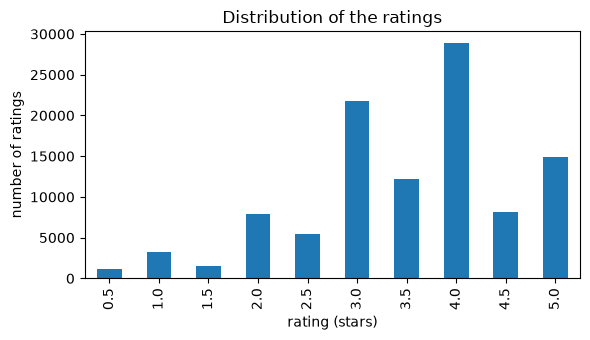

Mean rating: 3.517
Median rating: 3.5
Ratings >= 4.0: 49.29 %
Half-star ratings: 27.22 %


In [5]:
# Distribution of the rating values.
counts = ratings["rating"].value_counts().sort_index()
shares = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"ratings": counts, "%": shares}).T)
fig, ax = plt.subplots(figsize=(6, 3.5))
counts.plot(kind="bar", ax=ax)
ax.set_title("Distribution of the ratings")
ax.set_xlabel("rating (stars)")
ax.set_ylabel("number of ratings")
plt.tight_layout()
plt.show()
print("Mean rating:", round(ratings["rating"].mean(), 3))
print("Median rating:", ratings["rating"].median())
print(
    f"Ratings >= {RELEVANT_RATING}:",
    round((ratings["rating"] >= RELEVANT_RATING).mean() * 100, 2), "%",
)
print(
    "Half-star ratings:",
    round((ratings["rating"] % 1 != 0).mean() * 100, 2), "%",
)

Ratings per user:


,count,mean,std,min,25%,50%,75%,max
0,668.0,157.7,319.7,20.0,35.0,70.5,153.0,5678.0


Ratings per movie:


,count,mean,std,min,25%,50%,75%,max
0,10325.0,10.2,22.8,1.0,1.0,3.0,8.0,325.0


Matrix: 668 users x 10325 movies
Filled cells: 1.53 %  (sparsity 0.9847)
Movies with at most 1 rating(s): 35.2 %
Movies with at most 2 rating(s): 49.3 %
Movies with at most 5 rating(s): 67.4 %
Movies with at most 10 rating(s): 79.1 %
Movies with at most 50 rating(s): 95.7 %
Movies with at least 5 ratings: 3855
Top 1% most rated movies (103) hold 16.6 % of the ratings
Top 10% most rated movies (1032) hold 60.8 % of the ratings
Top 20% most rated movies (2065) hold 77.3 % of the ratings
Top 10 % most active users hold 49.1 % of the ratings


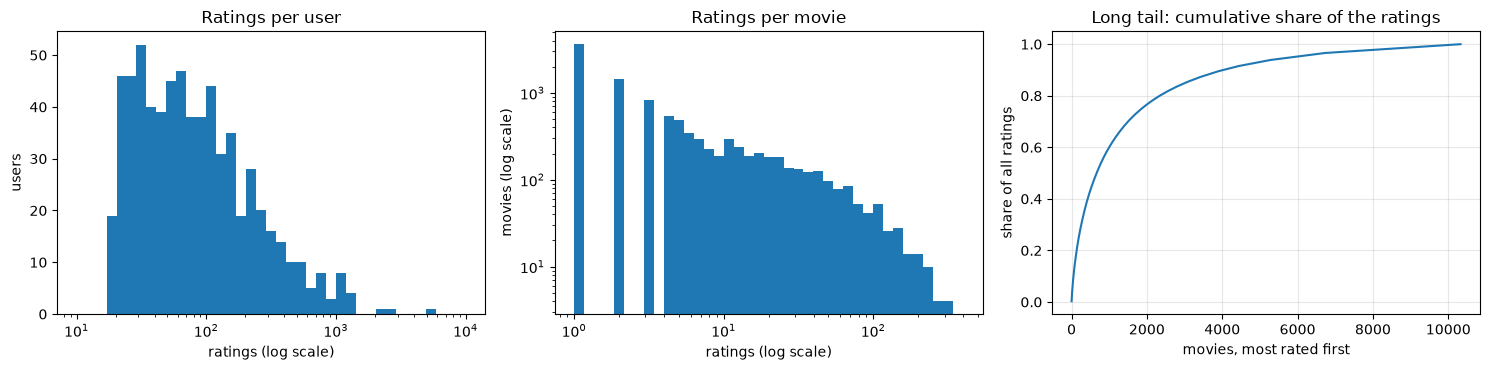

In [6]:
# Ratings per user and per movie (long tail) and sparsity of the matrix.
per_user = ratings.groupby("userId").size()
per_movie = ratings.groupby("movieId").size()
n_users, n_rated = len(per_user), len(per_movie)
print("Ratings per user:")
display(per_user.describe().round(1).to_frame().T)
print("Ratings per movie:")
display(per_movie.describe().round(1).to_frame().T)

density = len(ratings) / (n_users * n_rated)
print(f"Matrix: {n_users} users x {n_rated} movies")
print(f"Filled cells: {density * 100:.2f} %  (sparsity {1 - density:.4f})")

for threshold in (1, 2, 5, 10, 50):
    print(
        f"Movies with at most {threshold} rating(s): "
        f"{(per_movie <= threshold).mean() * 100:.1f} %"
    )
print(
    f"Movies with at least {MIN_RATINGS} ratings:",
    (per_movie >= MIN_RATINGS).sum(),
)
ordered = per_movie.sort_values(ascending=False)
cumulative = ordered.cumsum() / ordered.sum()
for share in (0.01, 0.10, 0.20):
    top = int(len(ordered) * share)
    print(
        f"Top {share:.0%} most rated movies ({top}) hold "
        f"{cumulative.iloc[top - 1] * 100:.1f} % of the ratings"
    )
user_ordered = per_user.sort_values(ascending=False)
print(
    "Top 10 % most active users hold",
    round(user_ordered.head(len(user_ordered) // 10).sum()
          / len(ratings) * 100, 1),
    "% of the ratings",
)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(per_user, bins=np.logspace(1, 4, 40))
axes[0].set_xscale("log")
axes[0].set_title("Ratings per user")
axes[0].set_xlabel("ratings (log scale)")
axes[0].set_ylabel("users")
axes[1].hist(per_movie, bins=np.logspace(0, 2.6, 40))
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Ratings per movie")
axes[1].set_xlabel("ratings (log scale)")
axes[1].set_ylabel("movies (log scale)")
axes[2].plot(np.arange(1, len(ordered) + 1), cumulative.to_numpy())
axes[2].set_title("Long tail: cumulative share of the ratings")
axes[2].set_xlabel("movies, most rated first")
axes[2].set_ylabel("share of all ratings")
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Most rated movies, and how the mean rating relates to popularity.
stats = (
    ratings.groupby("movieId")["rating"].agg(n_ratings="size", mean="mean")
    .join(movies.set_index("movieId")[["title", "genres"]])
)
display(
    stats.sort_values("n_ratings", ascending=False)
    .head(10)[["title", "n_ratings", "mean"]].round(2)
)
print("Best mean rating without a minimum number of ratings:")
display(
    stats.sort_values(["mean", "n_ratings"], ascending=False)
    .head(5)[["title", "n_ratings", "mean"]]
)
bands = pd.cut(
    stats["n_ratings"], [0, 1, 4, 19, 49, 99, np.inf],
    labels=["1", "2-4", "5-19", "20-49", "50-99", "100+"],
)
display(
    stats.groupby(bands, observed=True)["mean"]
    .agg(movies="size", mean_rating="mean", std="std").round(3)
)
print(
    "Spearman correlation between number of ratings and mean rating:",
    round(stats["n_ratings"].corr(stats["mean"], method="spearman"), 3),
)

,title,n_ratings,mean
movieId,,,
296,Pulp Fiction (1994),325,4.16
356,Forrest Gump (1994),311,4.14
318,"Shawshank Redemption, The (1994)",308,4.45
480,Jurassic Park (1993),294,3.66
593,"Silence of the Lambs, The (1991)",290,4.19
260,Star Wars: Episode IV - A New Hope (1977),273,4.19
2571,"Matrix, The (1999)",261,4.26
589,Terminator 2: Judgment Day (1991),253,3.96
527,Schindler's List (1993),248,4.30


Best mean rating without a minimum number of ratings:


,title,n_ratings,mean
movieId,,,
1546,Schizopolis (1996),2,5.0
1925,Wings (1927),2,5.0
6902,Interstate 60 (2002),2,5.0
31437,Nobody Knows (Dare mo shiranai) (2004),2,5.0
32554,Memories (Memorîzu) (1995),2,5.0


,movies,mean_rating,std
n_ratings,,,
1,3638,2.965,1.013
2-4,2832,3.166,0.758
5-19,2533,3.296,0.589
20-49,867,3.499,0.465
50-99,302,3.603,0.409
100+,153,3.805,0.354


Spearman correlation between number of ratings and mean rating: 0.225


,movies,ratings,mean_rating,% of movies
genre,,,,
Drama,5220,46960,3.650,50.5
Comedy,3515,38055,3.421,34.0
Thriller,2187,29288,3.496,21.2
Romance,1788,19094,3.544,17.3
Action,1737,31205,3.451,16.8
Crime,1440,18291,3.642,13.9
Adventure,1164,23076,3.518,11.3
Horror,1001,7983,3.281,9.7
Sci-Fi,860,16795,3.454,8.3


Genres per movie: {'count': 10329.0, 'mean': 2.24, 'std': 1.1, 'min': 0.0, '25%': 1.0, '50%': 2.0, '75%': 3.0, 'max': 10.0}
Distinct genres: 19
Distinct genre combinations: 938


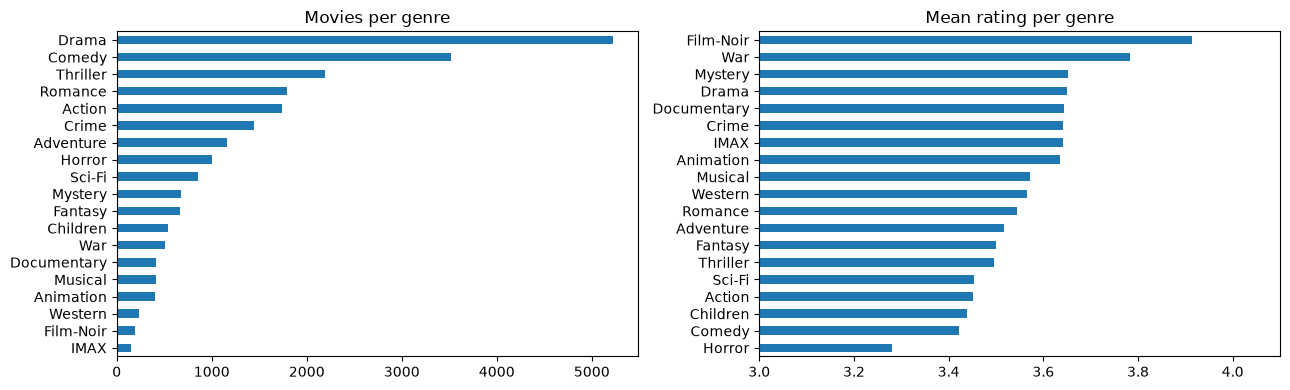

In [8]:
# Genres: number of movies, number of ratings and mean rating.
genre_of_movie = movies[["movieId", "genre_list"]].explode("genre_list")
genre_of_movie = genre_of_movie.dropna().rename(
    columns={"genre_list": "genre"}
)
genre_ratings = ratings.merge(genre_of_movie, on="movieId")
genre_table = pd.DataFrame({
    "movies": genre_of_movie.groupby("genre").size(),
    "ratings": genre_ratings.groupby("genre").size(),
    "mean_rating": genre_ratings.groupby("genre")["rating"].mean().round(3),
}).sort_values("movies", ascending=False)
genre_table["% of movies"] = (
    genre_table["movies"] / len(movies) * 100
).round(1)
display(genre_table)
print(
    "Genres per movie:",
    movies["genre_list"].str.len().describe().round(2).to_dict(),
)
print("Distinct genres:", len(genre_table))
print(
    "Distinct genre combinations:",
    movies["genres"].nunique(),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
genre_table["movies"].sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Movies per genre")
axes[0].set_ylabel("")
genre_table["mean_rating"].sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_xlim(3, 4.1)
axes[1].set_title("Mean rating per genre")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

,ratings,mean,active_users
date,,,
1996,5808,3.485,106
1997,4079,3.651,56
1998,2279,3.797,24
1999,6088,3.563,39
2000,11282,3.566,79
2001,3782,3.713,42
2002,5273,3.384,42
2003,4983,3.536,45
2004,5358,3.344,45


year,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010
movies,1,3,54,277,401,465,509,661,1254,2247,3027,1428


Ratings given to movies released from 2010 on: 5.23 %
Median release year of a rated movie: 1995


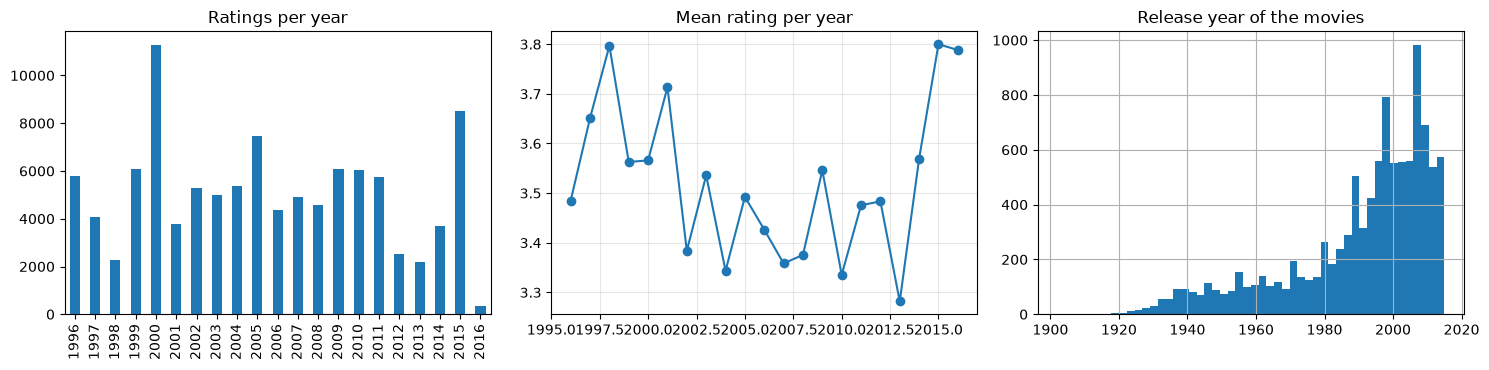

In [9]:
# Ratings over time, and release year of the movies.
by_year = ratings.groupby(ratings["date"].dt.year)["rating"].agg(
    ratings="size", mean="mean"
)
by_year["active_users"] = ratings.groupby(ratings["date"].dt.year)[
    "userId"
].nunique()
display(by_year.round(3))

decade = (movies["year"] // 10 * 10).dropna().astype(int)
display(decade.value_counts().sort_index().to_frame("movies").T)
rated_year = ratings.merge(movies[["movieId", "year"]], on="movieId")
print(
    "Ratings given to movies released from 2010 on:",
    round((rated_year["year"] >= 2010).mean() * 100, 2), "%",
)
print(
    "Median release year of a rated movie:",
    int(rated_year["year"].median()),
)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
by_year["ratings"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Ratings per year")
axes[0].set_xlabel("")
by_year["mean"].plot(marker="o", ax=axes[1])
axes[1].set_title("Mean rating per year")
axes[1].set_xlabel("")
axes[1].grid(alpha=0.3)
movies["year"].dropna().astype(int).hist(bins=50, ax=axes[2])
axes[2].set_title("Release year of the movies")
plt.tight_layout()
plt.show()

**Exploration findings:**

- **Ratings are generous:** the mean is 3.52 and the median 3.5; the most frequent values are 4.0 (27.4 %), 3.0 (20.6 %) and 5.0 (14.1 %). **49.3 %** of the ratings are 4 or more, which is the threshold used here for "the user liked it". Half-star ratings are only 27.2 % of the total.
- **The matrix is almost empty:** 668 users x 10,325 rated movies with 105,339 ratings means that **1.53 %** of the cells are filled (sparsity 0.985). Any method must work with very few ratings in common between two movies.
- **Long tail of movies:** the median movie has 3 ratings and the mean is 10.2; **35.2 %** of the movies have a single rating and 67.4 % have 5 or fewer, while the most rated one (*Pulp Fiction*) has 325. The 10 % most rated movies hold **60.8 %** of all ratings. Only **3,855 movies** have 5 or more ratings: these are the ones collaborative filtering can say something about.
- **Users are also uneven:** the median user rated 70.5 movies and the most active one 5,678; the 10 % most active users hold 49.1 % of the ratings.
- **Popular movies are also better rated:** the mean rating grows from 2.97 for movies with one rating to 3.81 for movies with 100 or more (Spearman correlation 0.225). Two consequences follow: (1) the best raw means are meaningless (the top of that list consists of movies with two 5-star ratings), so a ranking by rating needs a **Bayesian average** or a minimum number of ratings; (2) recommending popular movies is a strong strategy by itself, so it must be the baseline.
- **Genres are coarse:** 19 genres, 2.24 per movie on average and 938 distinct combinations. Drama appears in 50.5 % of the movies and Comedy in 34.0 %. The mean rating differs little between genres (from 3.28 for Horror to 3.91 for Film-Noir), so genres alone can hardly tell a good movie from a bad one.
- **Time:** the yearly number of ratings is irregular (11,282 in 2000, 2,184 in 2013, 8,526 in 2015), and few users are active each year (between 24 and 106, leaving aside the 11 of January 2016). Recent movies are scarce: those released from 2010 on receive only **5.2 %** of the ratings, and the median release year of a rated movie is 1995.

**Preprocessing decisions:**
- No rows are removed: there are no missing values or duplicates.
- Unrated cells are stored as 0 (the minimum rating is 0.5, so 0 is unambiguous).
- A movie needs at least `MIN_RATINGS = 5` ratings to get collaborative neighbours, and two movies need at least `MIN_CO_RATINGS = 3` users in common; similarities are also shrunk when the overlap is small (section 4). This keeps similarities based on a couple of ratings from dominating.
- Whether to subtract each user's mean rating (mean-centring) is treated as a hyperparameter and tested, not assumed.
- The split is **per user** and random (not by date): with so few users active in any given year, a single chronological cut-off could leave many users without test ratings.

## 4. Model

There is no `Pipeline` and no cross-validation of a classifier here. Instead:

1. **Split per user.** A random 20 % of *each user's* ratings is the **test** set. From the remaining 80 %, another 20 % is a **validation** set used to choose parameters. Similarities are always computed from the training part only.
2. **Protocol A - full history.** The recommender sees all the training ratings of a user and must rank the movies the user has not rated. This is the usual way to compare recommenders.
3. **Protocol B - one seed movie.** The recommender sees **one** movie the user liked (the seed) and returns its neighbours. This is what the JarvisTEC command does, so this protocol decides which neighbour table is served.
4. Parameters are chosen on validation by NDCG@10; the test ratings are not used for any choice and appear only in section 5.

The two protocols are tuned separately, so the item-based configuration that wins protocol A is **not** the one that is served; both are given below as printed.

In [10]:
# Per-user random hold-out: every user keeps ratings in every part.
def split_per_user(frame, fraction, seed):
    """Hold out `fraction` of each user's ratings, chosen at random."""
    rng = np.random.default_rng(seed)
    keys = pd.Series(rng.random(len(frame)), index=frame.index)
    position = keys.groupby(frame["userId"]).rank(method="first")
    size = frame.groupby("userId")["userId"].transform("size")
    held = position <= np.floor(size * fraction)
    return frame[~held], frame[held]


ratings = ratings.sort_values(["userId", "movieId"]).reset_index(drop=True)
train_full, test = split_per_user(ratings, TEST_FRACTION, SEED)
train, validation = split_per_user(train_full, VALIDATION_FRACTION, SEED + 1)

# Fixed positions: every user and every movie of movies.csv.
user_ids = np.sort(ratings["userId"].unique())
movie_ids = movies["movieId"].to_numpy()
user_pos = {user: i for i, user in enumerate(user_ids)}
movie_pos = {movie: i for i, movie in enumerate(movie_ids)}
N_USERS, N_MOVIES = len(user_ids), len(movie_ids)


def to_matrix(frame):
    """Dense users x movies matrix; 0 means 'not rated' (min rating 0.5)."""
    matrix = np.zeros((N_USERS, N_MOVIES), dtype=np.float32)
    rows = frame["userId"].map(user_pos).to_numpy()
    columns = frame["movieId"].map(movie_pos).to_numpy()
    matrix[rows, columns] = frame["rating"].to_numpy()
    return matrix


R_train, R_validation = to_matrix(train), to_matrix(validation)
R_train_full, R_test = to_matrix(train_full), to_matrix(test)

split_table = pd.DataFrame({
    "ratings": [len(train), len(validation), len(train_full), len(test)],
    "relevant (>= 4)": [
        (part["rating"] >= RELEVANT_RATING).sum()
        for part in (train, validation, train_full, test)
    ],
    "min ratings per user": [
        part.groupby("userId").size().min()
        for part in (train, validation, train_full, test)
    ],
    "rated movies": [
        part["movieId"].nunique()
        for part in (train, validation, train_full, test)
    ],
}, index=["train", "validation", "train + validation", "test"])
display(split_table)
print(
    "Test movies never rated in train + validation:",
    (~test["movieId"].isin(train_full["movieId"])).sum(), "ratings",
)
assert len(train) + len(validation) + len(test) == len(ratings)

,ratings,relevant (>= 4),min ratings per user,rated movies
train,67868,33571,13,8816
validation,16659,8155,3,4837
train + validation,84527,41726,16,9553
test,20812,10197,4,5379


Test movies never rated in train + validation: 842 ratings


In [11]:
# Ranking metrics for a top-N list per user.
DISCOUNT = 1.0 / np.log2(np.arange(2, TOP_N + 2))


def top_n_lists(scores, seen, n=TOP_N, chunk=64):
    """Best `n` movies per user, never one the user already rated."""
    tops, valids = [], []
    for start in range(0, len(scores), chunk):  # chunks keep memory low
        rows = slice(start, start + chunk)
        block = np.where(seen[rows] > 0, -np.inf, scores[rows])
        top = np.argpartition(-block, n, axis=1)[:, :n]
        best = np.take_along_axis(block, top, axis=1)
        order = np.argsort(-best, axis=1, kind="stable")
        tops.append(np.take_along_axis(top, order, axis=1))
        valids.append(np.isfinite(np.take_along_axis(best, order, axis=1)))
    return np.vstack(tops), np.vstack(valids)


def evaluate(scores, seen, held_out):
    """Mean HR, precision, recall and NDCG at TOP_N, plus coverage."""
    top, valid = top_n_lists(scores, seen)
    relevant = held_out >= RELEVANT_RATING
    hits = np.take_along_axis(relevant, top, axis=1) & valid
    n_relevant = relevant.sum(axis=1)
    users = n_relevant > 0  # users with something to find
    hits, n_relevant = hits[users], n_relevant[users]
    dcg = (hits * DISCOUNT).sum(axis=1)
    ideal = np.cumsum(DISCOUNT)[np.minimum(n_relevant, TOP_N) - 1]
    per_user = pd.DataFrame({
        "hit": hits.any(axis=1).astype(float),
        "precision": hits.sum(axis=1) / TOP_N,
        "recall": hits.sum(axis=1) / n_relevant,
        "ndcg": dcg / ideal,
    }, index=np.flatnonzero(users))
    recommended = np.unique(top[users][valid[users]])
    result = {
        f"hit_rate@{TOP_N}": per_user["hit"].mean(),
        f"precision@{TOP_N}": per_user["precision"].mean(),
        f"recall@{TOP_N}": per_user["recall"].mean(),
        f"ndcg@{TOP_N}": per_user["ndcg"].mean(),
        "coverage": len(recommended) / N_MOVIES,
    }
    return result, per_user, top


NDCG = f"ndcg@{TOP_N}"
print(
    "Users evaluated on validation:",
    int(((R_validation >= RELEVANT_RATING).sum(axis=1) > 0).sum()),
    "| on test:",
    int(((R_test >= RELEVANT_RATING).sum(axis=1) > 0).sum()),
)

Users evaluated on validation: 647 | on test: 655


In [12]:
# Non-personalised baselines: the same list for every user.
def score_random(R, seed=SEED):
    return np.random.default_rng(seed).random(R.shape, dtype=np.float32)


def score_popularity(R):
    """Most rated movies first."""
    counts = (R > 0).sum(axis=0).astype(np.float32)
    return np.broadcast_to(counts, R.shape)  # same row for every user


def bayesian_average(R, prior):
    """Mean rating shrunk towards the global mean by `prior` ratings."""
    counts = (R > 0).sum(axis=0)
    sums = R.sum(axis=0, dtype=np.float64)
    global_mean = sums.sum() / counts.sum()
    return (sums + prior * global_mean) / (counts + prior)


def score_bayesian(R, prior):
    return np.broadcast_to(bayesian_average(R, prior), R.shape)


validation_rows = []


def record(approach, parameters, scores, store=validation_rows):
    result, _, _ = evaluate(scores, R_train, R_validation)
    store.append({"approach": approach, **parameters, **result})
    return result


record("Random", {}, score_random(R_train))
record("Popularity (most rated)", {}, score_popularity(R_train))
for prior in (5, 10, 25, 50, 100, 200):
    record("Bayesian average", {"prior": prior}, score_bayesian(R_train, prior))
display(pd.DataFrame(validation_rows).round(4))

,approach,hit_rate@10,precision@10,recall@10,ndcg@10,coverage,prior
0,Random,0.0155,0.0015,0.0008,0.0016,0.4665,NaN
1,Popularity (most rated),0.4451,0.0765,0.0859,0.1039,0.0037,NaN
2,Bayesian average,0.2751,0.0366,0.0396,0.0505,0.0021,5.0
3,Bayesian average,0.3539,0.0547,0.0513,0.0675,0.0027,10.0
4,Bayesian average,0.4065,0.0689,0.0684,0.0855,0.0028,25.0
5,Bayesian average,0.4374,0.0779,0.0820,0.0968,0.0031,50.0
6,Bayesian average,0.4343,0.0779,0.0820,0.0991,0.0031,100.0
7,Bayesian average,0.4482,0.0798,0.0842,0.1013,0.0032,200.0


In [13]:
# Content-based recommender: genres only (TF-IDF weighted).
genre_names = sorted(genre_table.index)
G = np.zeros((N_MOVIES, len(genre_names)), dtype=np.float32)
for row, genre_list in enumerate(movies["genre_list"]):
    for genre in genre_list:
        G[row, genre_names.index(genre)] = 1.0
idf = np.log(N_MOVIES / G.sum(axis=0))
G_tfidf = (G * idf).astype(np.float32)
norms = np.linalg.norm(G_tfidf, axis=1, keepdims=True)
G_tfidf = G_tfidf / np.where(norms == 0, 1, norms)


def user_means(R):
    rated = R > 0
    means = R.sum(axis=1) / np.maximum(rated.sum(axis=1), 1)
    return means.astype(np.float32)


def centered(R):
    """Ratings minus the user's mean; unrated cells stay at 0."""
    return (R - user_means(R)[:, None]) * (R > 0)


def weights(R, profile):
    """How much each rated movie counts in the user's profile."""
    if profile == "rating":
        return R
    if profile == "liked":
        return (R >= RELEVANT_RATING).astype(np.float32)
    return centered(R)  # "centered": disliked movies push away


def score_content(R, profile, seed=SEED):
    """Cosine between the user's genre profile and each movie's genres.

    The profile adds the genre vectors of the user's movies (see
    `weights`). Movies with the same genres tie; ties are broken at
    random so that the order of the file does not help.
    """
    taste = weights(R, profile) @ G_tfidf
    norms = np.linalg.norm(taste, axis=1, keepdims=True)
    scores = (taste / np.where(norms == 0, 1, norms)) @ G_tfidf.T
    noise = np.random.default_rng(seed).random(scores.shape, dtype=np.float32)
    return scores + noise * 1e-6


for profile in ("rating", "liked", "centered"):
    record(
        "Content-based (genres)", {"profile": profile},
        score_content(R_train, profile),
    )
display(pd.DataFrame(validation_rows).tail(3).round(4))

,approach,hit_rate@10,precision@10,recall@10,ndcg@10,coverage,prior,profile
8,Content-based (genres),0.0433,0.0045,0.0069,0.0059,0.1468,NaN,rating
9,Content-based (genres),0.0448,0.0048,0.0050,0.0060,0.1818,NaN,liked
10,Content-based (genres),0.0294,0.0034,0.0025,0.0033,0.3774,NaN,centered


In [14]:
# Item-based collaborative filtering (Sarwar et al., 2001).
def item_cosine(R, center):
    """Cosine between the rating columns of the movies, and their overlap.

    center=True subtracts each user's mean first (adjusted cosine).
    Unrated cells count as 0, so the norms use every rating of a movie.
    Only movies with at least MIN_RATINGS ratings take part.
    """
    rated = R > 0
    items = np.flatnonzero(rated.sum(axis=0) >= MIN_RATINGS)
    X = (centered(R) if center else R)[:, items]
    cosine = X.T @ X
    norms = np.sqrt(np.diag(cosine))
    norms[norms == 0] = 1.0
    cosine /= norms[:, None]
    cosine /= norms[None, :]
    B = rated[:, items].astype(np.float32)
    common = B.T @ B  # users who rated both movies
    return items, cosine, common


def damp(cosine, common, shrink):
    """Shrink similarities supported by few common users.

    similarity = cosine * n / (n + shrink), n = users in common; it is 0
    below MIN_CO_RATINGS common users, for negative values and for the
    movie itself.
    """
    similarity = cosine * (common / (common + shrink))
    similarity[common < MIN_CO_RATINGS] = 0.0
    np.maximum(similarity, 0.0, out=similarity)
    np.fill_diagonal(similarity, 0.0)
    return similarity


def keep_top_k(similarity, k):
    """Keep only the k most similar movies of each row."""
    if k >= similarity.shape[1]:
        return similarity
    threshold = -np.partition(-similarity, k - 1, axis=1)[:, [k - 1]]
    return np.where(similarity >= threshold, similarity, 0.0)


def score_item_cf(R, center, shrink, k, profile, fitted=None):
    """Score of a movie = sum of its similarity to the user's movies."""
    items, cosine, common = fitted or item_cosine(R, center)
    neighbors = keep_top_k(damp(cosine, common, shrink), k)
    scores = np.full(R.shape, -np.inf, dtype=np.float32)
    scores[:, items] = weights(R, profile)[:, items] @ neighbors.T
    return scores


started = time.time()
for center in (False, True):
    fitted = item_cosine(R_train, center)
    for shrink in (0, 10, 25, 50):
        for k in (20, 50, 200):
            for profile in ("rating", "liked", "centered"):
                parameters = {
                    "center": center, "shrink": shrink, "k": k,
                    "profile": profile,
                }
                record(
                    "Item-based CF", parameters,
                    score_item_cf(R_train, fitted=fitted, **parameters),
                )
del fitted
item_cf_grid = pd.DataFrame(validation_rows).query(
    "approach == 'Item-based CF'"
).drop(columns=["approach", "prior"])
print(
    len(item_cf_grid), "combinations in", round(time.time() - started),
    "s; movies with neighbours in train:",
    int(((R_train > 0).sum(axis=0) >= MIN_RATINGS).sum()),
)
display(item_cf_grid.sort_values(NDCG, ascending=False).head(10).round(4))
for column in ("center", "shrink", "k", "profile"):
    display(
        item_cf_grid.groupby(column)[[NDCG, "coverage"]]
        .agg(["mean", "max"]).round(4)
    )

72 combinations in 17 s; movies with neighbours in train: 2881


,hit_rate@10,precision@10,recall@10,ndcg@10,coverage,profile,center,shrink,k
27,0.6244,0.1209,0.1505,0.1676,0.0442,liked,False,10.0,200.0
36,0.6136,0.1187,0.1454,0.1666,0.0338,liked,False,25.0,200.0
45,0.5966,0.1158,0.1413,0.1646,0.0292,liked,False,50.0,200.0
35,0.5997,0.1167,0.1469,0.1640,0.0278,rating,False,25.0,200.0
44,0.5904,0.1153,0.1436,0.1629,0.0233,rating,False,50.0,200.0
33,0.5765,0.1190,0.1424,0.1618,0.0461,liked,False,25.0,50.0
41,0.5889,0.1142,0.1390,0.1615,0.0337,rating,False,50.0,50.0
42,0.5858,0.1164,0.1381,0.1607,0.0414,liked,False,50.0,50.0
32,0.5750,0.1156,0.1384,0.1604,0.0398,rating,False,25.0,50.0
77,0.5858,0.1167,0.1308,0.1597,0.0354,rating,True,50.0,50.0


ndcg@10         coverage        
          mean     max     mean     max
center                                 
False   0.1455  0.1676   0.0642  0.1233
True    0.1292  0.1597   0.0751  0.1647

ndcg@10         coverage        
          mean     max     mean     max
shrink                                 
0.0     0.1063  0.1561   0.1193  0.1647
10.0    0.1433  0.1676   0.0637  0.0861
25.0    0.1490  0.1666   0.0507  0.0739
50.0    0.1508  0.1646   0.0448  0.0686

ndcg@10         coverage        
         mean     max     mean     max
k                                     
20.0   0.1376  0.1589   0.0779  0.1647
50.0   0.1390  0.1618   0.0703  0.1514
200.0  0.1356  0.1676   0.0608  0.1305

ndcg@10         coverage        
            mean     max     mean     max
profile                                  
centered  0.1214  0.1428   0.0853  0.1647
liked     0.1456  0.1676   0.0656  0.1588
rating    0.1451  0.1640   0.0581  0.1512

In [15]:
# Latent factors: truncated SVD of the rating matrix (unrated cells = 0).
from sklearn.decomposition import TruncatedSVD


def score_svd(R, n_components):
    svd = TruncatedSVD(n_components=n_components, random_state=SEED)
    user_factors = svd.fit_transform(R)
    return (user_factors @ svd.components_).astype(np.float32)


for n_components in (5, 10, 20, 30, 50, 100):
    record(
        "Truncated SVD", {"n_components": n_components},
        score_svd(R_train, n_components),
    )
display(
    pd.DataFrame(validation_rows).query("approach == 'Truncated SVD'")
    [["n_components", f"hit_rate@{TOP_N}", f"precision@{TOP_N}",
      f"recall@{TOP_N}", NDCG, "coverage"]].round(4)
)

,n_components,hit_rate@10,precision@10,recall@10,ndcg@10,coverage
83,5.0,0.5410,0.1042,0.1168,0.1380,0.0138
84,10.0,0.5719,0.1145,0.1325,0.1522,0.0208
85,20.0,0.6074,0.1213,0.1520,0.1703,0.0316
86,30.0,0.6198,0.1235,0.1575,0.1763,0.0380
87,50.0,0.6136,0.1107,0.1546,0.1645,0.0470
88,100.0,0.5363,0.0852,0.1290,0.1285,0.0623


In [16]:
# Best configuration of every approach on VALIDATION (by NDCG@10).
validation_table = pd.DataFrame(validation_rows)
best_rows = validation_table.loc[
    validation_table.groupby("approach")[NDCG].idxmax()
].sort_values(NDCG, ascending=False)
parameter_columns = [
    "prior", "center", "shrink", "k", "profile", "n_components",
]
BEST_PARAMETERS = {}
for _, row in best_rows.iterrows():
    BEST_PARAMETERS[row["approach"]] = {
        column: (row[column].item() if hasattr(row[column], "item")
                 else row[column])
        for column in parameter_columns if pd.notna(row[column])
    }
for parameters in BEST_PARAMETERS.values():
    for column in ("prior", "shrink", "k", "n_components"):
        if column in parameters:
            parameters[column] = int(parameters[column])
    if "center" in parameters:
        parameters["center"] = bool(parameters["center"])
display(
    best_rows.drop(columns=parameter_columns).set_index("approach").round(4)
)
for approach, parameters in BEST_PARAMETERS.items():
    print(f"{approach}: {parameters or 'no parameters'}")

PERSONALISED = ["Item-based CF", "Truncated SVD", "Content-based (genres)"]
BEST = best_rows.loc[best_rows["approach"].isin(PERSONALISED)].iloc[0][
    "approach"
]
print("\nBest personalised approach on validation:", BEST)

,hit_rate@10,precision@10,recall@10,ndcg@10,coverage
approach,,,,,
Truncated SVD,0.6198,0.1235,0.1575,0.1763,0.0380
Item-based CF,0.6244,0.1209,0.1505,0.1676,0.0442
Popularity (most rated),0.4451,0.0765,0.0859,0.1039,0.0037
Bayesian average,0.4482,0.0798,0.0842,0.1013,0.0032
Content-based (genres),0.0448,0.0048,0.0050,0.0060,0.1818
Random,0.0155,0.0015,0.0008,0.0016,0.4665


Truncated SVD: {'n_components': 30}
Item-based CF: {'center': False, 'shrink': 10, 'k': 200, 'profile': 'liked'}
Popularity (most rated): no parameters
Bayesian average: {'prior': 200}
Content-based (genres): {'profile': 'liked'}
Random: no parameters

Best personalised approach on validation: Truncated SVD


In [17]:
# Served scenario: the assistant only knows ONE movie the user liked.
# The list is the neighbours of that seed movie; it is scored against
# the user's held-out relevant movies, like before.
N_DRAWS = 5  # seed movies tried per user (results are averaged)


def draw_seeds(R, seed=SEED):
    """N_DRAWS random liked movies per user (-1: nothing to seed with)."""
    rng = np.random.default_rng(seed)
    known = (R > 0).sum(axis=0) >= MIN_RATINGS
    seeds = np.full((N_DRAWS, N_USERS), -1)
    for user in range(N_USERS):
        liked = np.flatnonzero((R[user] >= RELEVANT_RATING) & known)
        if len(liked):
            seeds[:, user] = rng.choice(liked, N_DRAWS)
    return seeds


def neighbor_table(items, similarity):
    """Scores of every movie given one seed movie per user."""
    position = np.full(N_MOVIES, -1)
    position[items] = np.arange(len(items))

    def table(draw):
        scores = np.full((N_USERS, N_MOVIES), -np.inf, dtype=np.float32)
        users = np.flatnonzero(draw >= 0)
        rows = similarity[position[draw[users]]]
        scores[np.ix_(users, items)] = np.where(rows > 0, rows, -np.inf)
        return scores

    return table


def popularity_table(R):
    return lambda draw: score_popularity(R)


def genre_table_for(R, seed=SEED):
    noise = np.random.default_rng(seed).random(
        (N_USERS, N_MOVIES), dtype=np.float32
    ) * 1e-6

    def table(draw):
        scores = G_tfidf[np.maximum(draw, 0)] @ G_tfidf.T + noise
        scores[draw < 0] = -np.inf
        return scores

    return table


def svd_item_similarity(R, n_components):
    """Cosine between the latent vectors of the movies."""
    svd = TruncatedSVD(n_components=n_components, random_state=SEED).fit(R)
    items = np.flatnonzero((R > 0).sum(axis=0) >= MIN_RATINGS)
    factors = (svd.components_.T * svd.singular_values_)[items]
    norms = np.linalg.norm(factors, axis=1, keepdims=True)
    factors = (factors / np.where(norms == 0, 1, norms)).astype(np.float32)
    similarity = factors @ factors.T
    np.fill_diagonal(similarity, 0.0)
    return items, similarity


def evaluate_seeded(table, R, held_out, seeds):
    """Average of `evaluate` over the N_DRAWS seed movies of each user."""
    results, frames, recommended = [], [], set()
    for draw in seeds:
        result, frame, top = evaluate(table(draw), R, held_out)
        results.append(result)
        frames.append(frame)
        recommended.update(np.unique(top[draw >= 0]).tolist())
    result = pd.DataFrame(results).mean().to_dict()
    result["coverage"] = len(recommended) / N_MOVIES
    return result, sum(frames) / len(frames)


validation_seeds = draw_seeds(R_train)
print("Users without a seed movie:", int((validation_seeds[0] < 0).sum()))
seeded_rows = []


def record_seeded(approach, parameters, table):
    result, _ = evaluate_seeded(table, R_train, R_validation, validation_seeds)
    seeded_rows.append({"approach": approach, **parameters, **result})


record_seeded("Popularity (most rated)", {}, popularity_table(R_train))
record_seeded("Content-based (genres)", {}, genre_table_for(R_train))
for center in (False, True):
    items, cosine, common = item_cosine(R_train, center)
    for shrink in (0, 10, 25, 50, 100, 200):
        record_seeded(
            "Item-based CF", {"center": center, "shrink": shrink},
            neighbor_table(items, damp(cosine, common, shrink)),
        )
del cosine, common
for n_components in (10, 20, 30, 50, 100):
    record_seeded(
        "Truncated SVD", {"n_components": n_components},
        neighbor_table(*svd_item_similarity(R_train, n_components)),
    )
seeded_validation = pd.DataFrame(seeded_rows)
display(seeded_validation.round(4))

seeded_best = seeded_validation.loc[
    seeded_validation.groupby("approach")[NDCG].idxmax()
].sort_values(NDCG, ascending=False)
SEEDED_PARAMETERS = {
    "Popularity (most rated)": {},
    "Content-based (genres)": {},
}
# Item-based CF: the smallest shrinkage within TOLERANCE of the best NDCG
# (more shrinkage keeps pushing the lists towards the most rated movies).
TOLERANCE = 0.002
cf_rows = seeded_validation.query("approach == 'Item-based CF'")
cf_rows = cf_rows[cf_rows[NDCG] >= cf_rows[NDCG].max() - TOLERANCE]
row = cf_rows.sort_values("shrink").iloc[0]
SEEDED_PARAMETERS["Item-based CF"] = {
    "center": bool(row["center"]), "shrink": int(row["shrink"]),
}
row = seeded_best.set_index("approach").loc["Truncated SVD"]
SEEDED_PARAMETERS["Truncated SVD"] = {
    "n_components": int(row["n_components"]),
}
print("Best configuration per approach (seed-movie protocol):")
for approach in seeded_best["approach"]:
    print(f"  {approach}: {SEEDED_PARAMETERS[approach] or 'no parameters'}")
SERVED = seeded_best.loc[
    seeded_best["approach"].isin(["Item-based CF", "Truncated SVD"])
].iloc[0]["approach"]
print("Best neighbour table on validation:", SERVED)

Users without a seed movie: 0


,approach,hit_rate@10,precision@10,recall@10,ndcg@10,coverage,center,shrink,n_components
0,Popularity (most rated),0.4451,0.0765,0.0859,0.1039,0.0037,NaN,NaN,NaN
1,Content-based (genres),0.0300,0.0032,0.0026,0.0038,0.7450,NaN,NaN,NaN
2,Item-based CF,0.2720,0.0376,0.0571,0.0552,0.2454,False,0.0,NaN
3,Item-based CF,0.3663,0.0533,0.0748,0.0761,0.2041,False,10.0,NaN
4,Item-based CF,0.3913,0.0589,0.0809,0.0841,0.1925,False,25.0,NaN
5,Item-based CF,0.4046,0.0616,0.0842,0.0877,0.1883,False,50.0,NaN
6,Item-based CF,0.4087,0.0628,0.0858,0.0899,0.1868,False,100.0,NaN
7,Item-based CF,0.4080,0.0632,0.0861,0.0907,0.1855,False,200.0,NaN
8,Item-based CF,0.1406,0.0170,0.0208,0.0235,0.2513,True,0.0,NaN
9,Item-based CF,0.2560,0.0342,0.0409,0.0478,0.2228,True,10.0,NaN


Best configuration per approach (seed-movie protocol):
  Popularity (most rated): no parameters
  Item-based CF: {'center': False, 'shrink': 100}
  Truncated SVD: {'n_components': 30}
  Content-based (genres): no parameters
Best neighbour table on validation: Item-based CF


**Approaches.**

- **Random** and **Popularity** (most rated movies first) are reference points. **Bayesian average** ranks by the mean rating shrunk towards the global mean by a prior of *m* ratings.
- **Content-based (genres):** every movie is a TF-IDF (term frequency-inverse document frequency) vector of its genres; a user (or a seed movie) is compared with every movie by cosine similarity. Movies with identical genres tie, and ties are broken at random.
- **Item-based collaborative filtering** (Sarwar et al., 2001): two movies are similar when the same users rate them. The similarity is the cosine between the two rating columns, multiplied by `n / (n + shrink)`, where `n` is the number of users who rated both, and set to 0 below 3 common users. With the full history, the score of a candidate is the sum of its similarities to the user's movies.
- **Truncated SVD** (latent factors; Koren et al., 2009): the rating matrix, with unrated cells as 0, is approximated by `n_components` factors, as in the PureSVD method of Cremonesi et al. (2010). With the full history the score is the reconstructed row; with a seed movie, it is the cosine between the movies' latent vectors.

**Which candidates were tuned.** Random and popularity have no parameters. In protocol A the others were tuned on validation: the Bayesian-average prior (6 values), the user profile of the content-based recommender (3 options), item-based CF (72 combinations of centring, shrink 0 / 10 / 25 / 50, 20 / 50 / 200 neighbours and user profile) and the number of SVD components (6 values). In protocol B only item-based CF (centring x shrink 0 to 200, 12 combinations) and the SVD factors (5 values) were tuned; the content-based table and popularity have nothing to tune there.

**Protocol A - full history (validation, 647 users).** Best configuration of each approach:

| Approach | Chosen parameters | HR@10 | P@10 | Recall@10 | NDCG@10 | Coverage |
|---|---|---|---|---|---|---|
| Truncated SVD | 30 components | 0.620 | 0.124 | 0.158 | **0.176** | 0.038 |
| Item-based CF | plain cosine, shrink 10, 200 neighbours, profile = liked movies | 0.624 | 0.121 | 0.151 | 0.168 | 0.044 |
| Popularity (most rated) | - | 0.445 | 0.077 | 0.086 | 0.104 | 0.004 |
| Bayesian average | prior 200 | 0.448 | 0.080 | 0.084 | 0.101 | 0.003 |
| Content-based (genres) | profile = liked movies | 0.045 | 0.005 | 0.005 | 0.006 | 0.182 |
| Random | - | 0.016 | 0.002 | 0.001 | 0.002 | 0.467 |

What the item-based grid (72 combinations, 2,881 movies with neighbours) shows:
- **Shrinkage matters most:** without it the mean NDCG@10 over the grid is 0.106; with shrink 10 to 50 it is 0.143 to 0.151. Similarities built on a handful of common users are unreliable.
- **Mean-centring did not help:** plain cosine averages 0.146 against 0.129 for the mean-centred ("adjusted") cosine, and a mean-centred user profile is the worst of the three profiles (0.121 against 0.146 for "liked movies"). A plausible explanation is that, for *ranking*, the fact that a user chose to watch a movie is itself informative, and centring discards part of that signal. Mean-centring is a common choice for *rating prediction*, so it was tested here instead of assumed.
- The Bayesian-average prior ended at the edge of its grid (200): the more the ranking resembles plain popularity, the better it scores. It was not explored further because its NDCG@10 stays below that of popularity for every prior tested.
- **Genres alone are barely better than random** on these metrics (NDCG@10 0.006 against 0.002). There are only 938 genre combinations for 10,329 movies, so the list is an arbitrary sample of the movies that share the user's favourite genres.

**Protocol B - one seed movie (validation).** Five random liked movies are tried per user and the results are averaged:

| Neighbour table | NDCG@10 | HR@10 | Coverage |
|---|---|---|---|
| Popularity (ignores the seed) | **0.104** | 0.445 | 0.004 |
| Item-based CF, plain cosine, shrink 0 / 10 / 25 / 50 / 100 / 200 | 0.055 / 0.076 / 0.084 / 0.088 / 0.090 / 0.091 | 0.272 to 0.409 | 0.245 to 0.186 |
| Item-based CF, mean-centred, shrink 0 to 200 | 0.024 to 0.065 | 0.141 to 0.328 | 0.251 to 0.206 |
| Truncated SVD factors (best: 30 components) | 0.055 | 0.274 | 0.261 |
| Content-based (genres) | 0.004 | 0.030 | 0.745 |

- Among the tables that actually depend on the seed movie, **item-based CF with plain cosine is clearly the best**, ahead of the SVD factors and far ahead of genres.
- **Popularity wins this protocol, and the served model scores below it on the selection metric.** On validation the popularity list reaches an NDCG@10 of 0.1039 and the item-based table that is served (plain cosine, shrink 100) reaches 0.0899, which is 0.014 lower; its hit rate is also lower (0.409 against 0.445). No configuration of the grid reaches the baseline (the best, shrink 200, has 0.0907). When only one movie is known, the neighbours of that movie hit fewer hidden favourites than the list of most rated movies given to everybody. No interval was computed for this difference on validation; the test set of section 5 gives one.
- **The shrinkage grid stops while NDCG@10 is still increasing.** For plain cosine it rises at every step (0.055, 0.076, 0.084, 0.088, 0.090, 0.091) and the largest value tried, 200, is the best, so the optimum may lie beyond the grid and was not looked for. Coverage falls at the same time (0.245 to 0.186): the lists concentrate on fewer, more rated movies. The rule used is "the smallest shrinkage within 0.002 NDCG@10 of the best", which gives **shrink = 100** (0.0899 against 0.0907 at 200; shrink 50, with 0.0877, is outside the tolerance). The 0.002 tolerance is a judgment call that trades a little NDCG for coverage.
- **The evaluation excludes the movies each user already rated; the deployed API cannot.** In this protocol the top-10 list of a user never contains a movie the user rated in the training part (the code masks them, as in protocol A). The API receives a title and nothing about the user, so it can only leave out the seed movie itself: a served list may contain movies the person has already seen. The numbers of protocol B therefore describe the neighbour table under a more favourable filter than the one in production. The same filter is applied to the popularity baseline, so the comparison between approaches is like for like.

**Model choice.** The served model is the **item-based collaborative filtering table: plain cosine, shrink 100, at least 5 ratings per movie and 3 common users per pair**. It is served **even though, by the selection metric alone, the popularity list would win protocol B** (0.1039 against 0.0899). The choice is a design decision, not a result of the metric:
- the command asks for movies like one title, and popularity ignores the title: it would answer every request with the same list (coverage 0.004 against 0.187 for the served table);
- among the tables that respond to the title it is the best on validation, well ahead of the SVD factors (0.055) and of genres (0.004);
- it is explainable ("people who rated this movie also rated...") and its artifact is a small table of neighbours, with nothing to compute per request.

**The two protocols use different item-based configurations.** The full-history results are those of `{'center': False, 'shrink': 10, 'k': 200, 'profile': 'liked'}`; the served one-seed table is `{'center': False, 'shrink': 100}`, with no limit on the number of neighbours during the evaluation. Shrink 100 was not part of the protocol A grid, so the served configuration was never scored with the full history. The full-history results show what item-based CF can do when it knows the user (it beats popularity by a wide margin and is close to SVD); they are not a measurement of the served table.

SVD is slightly better with the full history, but its item-to-item similarities are much worse (0.055 against 0.090), and the service needs item-to-item similarities.

## 5. Evaluation

Every approach is refitted on train + validation with the parameters chosen above. The chosen model is evaluated on the held-out test ratings (20,812 ratings, 655 users with at least one relevant hidden movie; the median user has 8), which were not used for training, model selection or tuning. Any other model or configuration scored on the test ratings below is shown for reference only and did not influence a choice.

,hit_rate@10,precision@10,recall@10,ndcg@10,coverage
Truncated SVD,0.7527,0.1986,0.2057,0.2759,0.0448
Item-based CF,0.7206,0.1979,0.1890,0.2691,0.0435
Popularity (most rated),0.5603,0.1224,0.1120,0.1651,0.0061
Bayesian average,0.5557,0.1153,0.1050,0.1433,0.0048
Content-based (genres),0.0626,0.0064,0.0035,0.0064,0.1771
Random,0.0153,0.0015,0.0004,0.0012,0.4714


Users evaluated: 655
Relevant held-out movies per evaluated user (median): 8.0


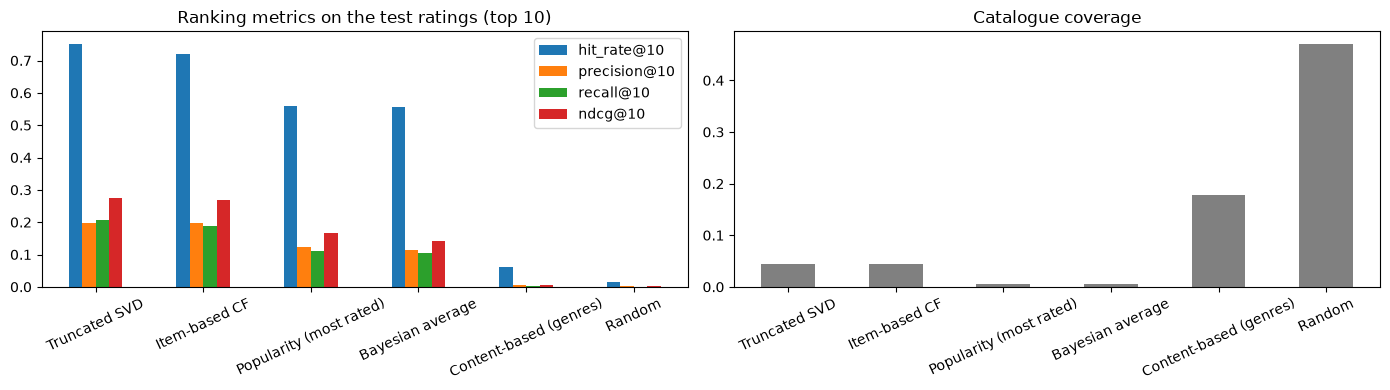

In [18]:
# Refit every approach on train + validation with the parameters chosen
# above, and evaluate ONCE on the test ratings.
SCORERS = {
    "Random": score_random,
    "Popularity (most rated)": score_popularity,
    "Bayesian average": score_bayesian,
    "Content-based (genres)": score_content,
    "Item-based CF": score_item_cf,
    "Truncated SVD": score_svd,
}
test_metrics, test_per_user, test_lists = {}, {}, {}
for approach, scorer in SCORERS.items():
    scores = scorer(R_train_full, **BEST_PARAMETERS[approach])
    result, per_user_metrics, top = evaluate(scores, R_train_full, R_test)
    test_metrics[approach] = {k: round(v, 4) for k, v in result.items()}
    test_per_user[approach] = per_user_metrics
    test_lists[approach] = top
del scores

test_table = pd.DataFrame(test_metrics).T.sort_values(NDCG, ascending=False)
display(test_table)
print("Users evaluated:", len(test_per_user[BEST]))
print(
    "Relevant held-out movies per evaluated user (median):",
    np.median((R_test >= RELEVANT_RATING).sum(axis=1)[
        test_per_user[BEST].index
    ]),
)

metric_columns = [c for c in test_table.columns if c != "coverage"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
test_table[metric_columns].plot(kind="bar", ax=axes[0])
axes[0].set_title(f"Ranking metrics on the test ratings (top {TOP_N})")
axes[0].tick_params(axis="x", rotation=25)
test_table["coverage"].plot(kind="bar", ax=axes[1], color="gray")
axes[1].set_title("Catalogue coverage")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

In [19]:
# Is the difference real? Bootstrap over users (2000 resamples, paired).
rng = np.random.default_rng(SEED)
evaluated = test_per_user[BEST].index.to_numpy()
samples = rng.integers(0, len(evaluated), size=(2000, len(evaluated)))
REFERENCE = "Popularity (most rated)"
rows = []
for approach in test_table.index:
    values = test_per_user[approach]["ndcg"].to_numpy()
    difference = values - test_per_user[REFERENCE]["ndcg"].to_numpy()
    means = values[samples].mean(axis=1)
    deltas = difference[samples].mean(axis=1)
    rows.append({
        "approach": approach,
        NDCG: values.mean(),
        "CI 2.5 %": np.percentile(means, 2.5),
        "CI 97.5 %": np.percentile(means, 97.5),
        "vs popularity": difference.mean(),
        "diff CI 2.5 %": np.percentile(deltas, 2.5),
        "diff CI 97.5 %": np.percentile(deltas, 97.5),
    })
bootstrap_table = pd.DataFrame(rows).set_index("approach").round(4)
display(bootstrap_table)

if BEST != "Item-based CF":
    difference = (
        test_per_user[BEST]["ndcg"].to_numpy()
        - test_per_user["Item-based CF"]["ndcg"].to_numpy()
    )
    deltas = difference[samples].mean(axis=1)
    print(
        f"{BEST} minus Item-based CF: {difference.mean():.4f} "
        f"[{np.percentile(deltas, 2.5):.4f}, "
        f"{np.percentile(deltas, 97.5):.4f}]"
    )

,ndcg@10,CI 2.5 %,CI 97.5 %,vs popularity,diff CI 2.5 %,diff CI 97.5 %
approach,,,,,,
Truncated SVD,0.2759,0.2571,0.2948,0.1108,0.0951,0.1261
Item-based CF,0.2691,0.2507,0.2877,0.1039,0.0889,0.1192
Popularity (most rated),0.1651,0.1496,0.1820,0.0000,0.0000,0.0000
Bayesian average,0.1433,0.1296,0.1578,-0.0218,-0.0317,-0.0123
Content-based (genres),0.0064,0.0043,0.0089,-0.1587,-0.1755,-0.1437
Random,0.0012,0.0005,0.0019,-0.1640,-0.1808,-0.1486


Truncated SVD minus Item-based CF: 0.0068 [-0.0048, 0.0187]


In [20]:
# Who is served well, and how popular are the recommended movies?
train_counts = (R_train_full > 0).sum(axis=0)
activity = pd.Series((R_train_full > 0).sum(axis=1)[evaluated], evaluated)
segments = pd.cut(
    activity, [0, 30, 60, 150, np.inf],
    labels=["<= 30 ratings", "31-60", "61-150", "> 150"],
)
compared = [
    "Popularity (most rated)", "Item-based CF", "Truncated SVD",
    "Content-based (genres)",
]
by_segment = pd.DataFrame({
    approach: test_per_user[approach]["ndcg"].groupby(
        segments, observed=True
    ).mean()
    for approach in compared
})
by_segment.insert(0, "users", segments.value_counts().sort_index())
print(f"{NDCG} by number of training ratings of the user:")
display(by_segment.round(4))

rows = []
for approach in test_table.index:
    top = test_lists[approach][evaluated]
    recommended = train_counts[top]
    rows.append({
        "approach": approach,
        "median ratings of a recommended movie": np.median(recommended),
        "distinct movies recommended": len(np.unique(top)),
        "share from the 100 most rated": round(
            np.isin(top, np.argsort(-train_counts)[:100]).mean(), 3
        ),
    })
display(pd.DataFrame(rows).set_index("approach"))
print(
    "Median ratings of a catalogue movie (train + validation):",
    np.median(train_counts[train_counts > 0]),
)

ndcg@10 by number of training ratings of the user:


,users,Popularity (most rated),Item-based CF,Truncated SVD,Content-based (genres)
<= 30 ratings,168,0.1191,0.1831,0.1959,0.0019
31-60,171,0.1157,0.2167,0.2512,0.0013
61-150,177,0.1353,0.2473,0.2640,0.0072
> 150,139,0.3195,0.4652,0.4181,0.0172


,median ratings of a recommended movie,distinct movies recommended,share from the 100 most rated
approach,,,
Truncated SVD,134.0,463,0.759
Item-based CF,132.0,449,0.763
Popularity (most rated),202.0,63,1.000
Bayesian average,183.0,50,0.995
Content-based (genres),4.0,1829,0.015
Random,2.0,4869,0.007


Median ratings of a catalogue movie (train + validation): 2.0


In [21]:
# Seed-movie protocol on the test ratings (parameters from validation).
test_seeds = draw_seeds(R_train_full)
SEEDED_TABLES = {
    "Popularity (most rated)": lambda R: popularity_table(R),
    "Content-based (genres)": lambda R: genre_table_for(R),
    "Item-based CF": lambda R, center, shrink: neighbor_table(
        *(lambda items, cosine, common: (
            items, damp(cosine, common, shrink)
        ))(*item_cosine(R, center))
    ),
    "Truncated SVD": lambda R, n_components: neighbor_table(
        *svd_item_similarity(R, n_components)
    ),
}
seeded_test_metrics, seeded_per_user = {}, {}
for approach, build in SEEDED_TABLES.items():
    table = build(R_train_full, **SEEDED_PARAMETERS[approach])
    result, frame = evaluate_seeded(table, R_train_full, R_test, test_seeds)
    seeded_test_metrics[approach] = {
        k: round(v, 4) for k, v in result.items()
    }
    seeded_per_user[approach] = frame
del table
seeded_test_table = pd.DataFrame(seeded_test_metrics).T.sort_values(
    NDCG, ascending=False
)
display(seeded_test_table)

rows = []
for approach in seeded_test_table.index:
    difference = (
        seeded_per_user[approach]["ndcg"].to_numpy()
        - seeded_per_user[REFERENCE]["ndcg"].to_numpy()
    )
    deltas = difference[samples].mean(axis=1)
    rows.append({
        "approach": approach,
        "vs popularity": difference.mean(),
        "diff CI 2.5 %": np.percentile(deltas, 2.5),
        "diff CI 97.5 %": np.percentile(deltas, 97.5),
    })
display(pd.DataFrame(rows).set_index("approach").round(4))
difference = (
    seeded_per_user["Item-based CF"]["ndcg"].to_numpy()
    - seeded_per_user["Truncated SVD"]["ndcg"].to_numpy()
)
deltas = difference[samples].mean(axis=1)
print(
    f"Item-based CF minus Truncated SVD: {difference.mean():.4f} "
    f"[{np.percentile(deltas, 2.5):.4f}, {np.percentile(deltas, 97.5):.4f}]"
)

,hit_rate@10,precision@10,recall@10,ndcg@10,coverage
Popularity (most rated),0.5603,0.1224,0.1120,0.1651,0.0061
Item-based CF,0.5066,0.1004,0.1068,0.1395,0.2012
Truncated SVD,0.3704,0.0620,0.0712,0.0857,0.2903
Content-based (genres),0.0498,0.0053,0.0039,0.0064,0.7565


,vs popularity,diff CI 2.5 %,diff CI 97.5 %
approach,,,
Popularity (most rated),0.0000,0.0000,0.0000
Item-based CF,-0.0256,-0.0379,-0.0138
Truncated SVD,-0.0794,-0.0943,-0.0651
Content-based (genres),-0.1587,-0.1755,-0.1436


Item-based CF minus Truncated SVD: 0.0538 [0.0472, 0.0607]


In [22]:
# Final similarity table, fitted on ALL the ratings (it is what the
# backend serves), and a qualitative check on well-known titles.
R_all = to_matrix(ratings)
CF = SEEDED_PARAMETERS["Item-based CF"]
final_items, cosine, common = item_cosine(R_all, CF["center"])
final_similarity = damp(cosine, common, CF["shrink"])
del cosine, common
neighbor_order = np.vstack([
    np.argsort(-row, kind="stable")[:SAVED_NEIGHBORS]
    for row in final_similarity
])
title_of = movies["title"].to_numpy()
position_in_final = {int(item): i for i, item in enumerate(final_items)}
all_counts = (R_all > 0).sum(axis=0)


def similar_movies(title, n=8):
    """Collaborative and genre-only neighbours of one movie."""
    movie = int(np.flatnonzero(title_of == title)[0])
    row = position_in_final[movie]
    collaborative = [
        (title_of[final_items[j]], round(float(final_similarity[row, j]), 3),
         int(all_counts[final_items[j]]))
        for j in neighbor_order[row, :n] if final_similarity[row, j] > 0
    ]
    by_genre = G_tfidf @ G_tfidf[movie]
    by_genre[movie] = -1
    # Stable sort: ties keep the file order.
    content = np.argsort(-by_genre, kind="stable")[:n]
    return pd.DataFrame({
        "item-based CF": [t for t, _, _ in collaborative],
        "similarity": [s for _, s, _ in collaborative],
        "ratings": [c for _, _, c in collaborative],
        "genres only": title_of[content][:len(collaborative)],
    })


EXAMPLES = [
    "Toy Story (1995)", "Matrix, The (1999)",
    "Star Wars: Episode IV - A New Hope (1977)",
    "Shawshank Redemption, The (1994)", "Titanic (1997)",
]
for title in EXAMPLES:
    genres = movies.loc[movies["title"] == title, "genres"].iloc[0]
    print(f"\n{title}  [{genres}]")
    display(similar_movies(title))

n_neighbors = (final_similarity > 0).sum(axis=1)
print("Movies with collaborative neighbours:", len(final_items))
print(
    f"Movies with fewer than {SAVED_NEIGHBORS} positive neighbours:",
    int((n_neighbors < SAVED_NEIGHBORS).sum()),
    "| with none:", int((n_neighbors == 0).sum()),
)
print(
    "Share of the catalogue with collaborative neighbours:",
    round(len(final_items) / N_MOVIES * 100, 1), "%; they hold",
    round(all_counts[final_items].sum() / len(ratings) * 100, 1),
    "% of the ratings",
)


Toy Story (1995)  [Adventure|Animation|Children|Comedy|Fantasy]


,item-based CF,similarity,ratings,genres only
0,Star Wars: Episode IV - A New Hope (1977),0.389,273,Antz (1998)
1,Star Wars: Episode VI - Return of the Jedi (1983),0.375,222,Toy Story 2 (1999)
2,Raiders of the Lost Ark (Indiana Jones and the...,0.338,224,"Adventures of Rocky and Bullwinkle, The (2000)"
3,Jurassic Park (1993),0.333,294,"Emperor's New Groove, The (2000)"
4,Independence Day (a.k.a. ID4) (1996),0.330,205,"Monsters, Inc. (2001)"
5,Back to the Future (1985),0.327,213,DuckTales: The Movie - Treasure of the Lost La...
6,Star Wars: Episode V - The Empire Strikes Back...,0.326,228,"Wild, The (2006)"
7,Mission: Impossible (1996),0.302,173,Shrek the Third (2007)



Matrix, The (1999)  [Action|Sci-Fi|Thriller]


,item-based CF,similarity,ratings,genres only
0,Fight Club (1999),0.423,207,Lawnmower Man 2: Beyond Cyberspace (1996)
1,"Lord of the Rings: The Fellowship of the Ring,...",0.397,189,Screamers (1995)
2,American Beauty (1999),0.396,216,Johnny Mnemonic (1995)
3,Star Wars: Episode V - The Empire Strikes Back...,0.394,228,Virtuosity (1995)
4,Raiders of the Lost Ark (Indiana Jones and the...,0.388,224,Timecop (1994)
5,Star Wars: Episode IV - A New Hope (1977),0.381,273,Blade Runner (1982)
6,Back to the Future (1985),0.371,213,Solo (1996)
7,Pulp Fiction (1994),0.352,325,"Arrival, The (1996)"



Star Wars: Episode IV - A New Hope (1977)  [Action|Adventure|Sci-Fi]


...


Shawshank Redemption, The (1994)  [Crime|Drama]


,item-based CF,similarity,ratings,genres only
0,Pulp Fiction (1994),0.491,325,Casino (1995)
1,"Silence of the Lambs, The (1991)",0.441,290,Shanghai Triad (Yao a yao yao dao waipo qiao) ...
2,Forrest Gump (1994),0.425,311,Dead Man Walking (1995)
3,Schindler's List (1993),0.398,248,"Hate (Haine, La) (1995)"
4,Braveheart (1995),0.397,248,"Young Poisoner's Handbook, The (1995)"
5,"Fugitive, The (1993)",0.389,244,The Glass Shield (1994)
6,"Usual Suspects, The (1995)",0.387,228,Heavenly Creatures (1994)
7,Jurassic Park (1993),0.375,294,Little Odessa (1994)



Titanic (1997)  [Drama|Romance]


,item-based CF,similarity,ratings,genres only
0,Men in Black (a.k.a. MIB) (1997),0.271,172,Sense and Sensibility (1995)
1,Back to the Future (1985),0.261,213,Leaving Las Vegas (1995)
2,Forrest Gump (1994),0.261,311,Persuasion (1995)
3,Jurassic Park (1993),0.254,294,Carrington (1995)
4,"Matrix, The (1999)",0.251,261,How to Make an American Quilt (1995)
5,Star Wars: Episode V - The Empire Strikes Back...,0.246,228,When Night Is Falling (1995)
6,"Sixth Sense, The (1999)",0.241,191,Bed of Roses (1996)
7,Saving Private Ryan (1998),0.238,187,Once Upon a Time... When We Were Colored (1995)


Movies with collaborative neighbours: 3855
Movies with fewer than 20 positive neighbours: 2 | with none: 0
Share of the catalogue with collaborative neighbours: 37.3 %; they hold 89.4 % of the ratings


**Protocol A - full history (test).** The item-based row is the full-history configuration, `{'center': False, 'shrink': 10, 'k': 200, 'profile': 'liked'}`, **not** the served table.

| Approach | HR@10 | P@10 | Recall@10 | NDCG@10 | Coverage |
|---|---|---|---|---|---|
| Truncated SVD | 0.753 | 0.199 | 0.206 | **0.276** | 0.045 |
| **Item-based CF** | 0.721 | 0.198 | 0.189 | 0.269 | 0.044 |
| Popularity (most rated) | 0.560 | 0.122 | 0.112 | 0.165 | 0.006 |
| Bayesian average | 0.556 | 0.115 | 0.105 | 0.143 | 0.005 |
| Content-based (genres) | 0.063 | 0.006 | 0.004 | 0.006 | 0.177 |
| Random | 0.015 | 0.002 | 0.000 | 0.001 | 0.471 |

- With a user's history, item-based CF puts at least one hidden favourite in the top 10 for **72 %** of the users, and on average 2 of its 10 movies are relevant, against 56 % and 1.2 for popularity.
- **The gain over popularity is statistically significant:** +0.104 NDCG@10, bootstrap 95 % interval [0.089, 0.119] over users.
- **SVD and item-based CF are statistically tied:** the difference is 0.007 with interval [-0.005, 0.019], which includes zero.
- The test values are higher than the validation ones for every approach except the random one (popularity 0.165 against 0.104), probably because the models are refitted on more ratings and each user has more hidden movies to find; the *order* of the approaches is the same.
- **By user activity:** both collaborative approaches beat popularity in every group. Item-based CF goes from an NDCG@10 of 0.183 for users with 30 training ratings or fewer (popularity 0.119) to 0.465 for users with more than 150, the only group where it is ahead of SVD (0.418; popularity 0.32).

**Protocol B - one seed movie (test).** This is the scenario the backend serves, with the served configuration `{'center': False, 'shrink': 100}` fitted on train + validation:

| Neighbour table | HR@10 | P@10 | Recall@10 | NDCG@10 | Coverage |
|---|---|---|---|---|---|
| Popularity (ignores the seed) | 0.560 | 0.122 | 0.112 | **0.165** | 0.006 |
| **Item-based CF (served)** | 0.507 | 0.100 | 0.107 | 0.140 | 0.201 |
| Truncated SVD factors | 0.370 | 0.062 | 0.071 | 0.086 | 0.290 |
| Content-based (genres) | 0.050 | 0.005 | 0.004 | 0.006 | 0.757 |

- **With a single seed movie the served model does not beat the popularity baseline.** Its NDCG@10 is 0.026 lower, with interval [-0.038, -0.014], so the difference is statistically significant. One movie is very little evidence about a person's taste, while recommending a title such as *The Shawshank Redemption* to everybody is a safe bet in a dataset where popular movies are also better rated.
- It **is** significantly better than the other approaches that use the seed: +0.054 NDCG@10 over the SVD factors, interval [0.047, 0.061], and about 22 times the NDCG@10 of genres.
- What it adds over popularity is that **the answer depends on the question**: its lists cover 20.1 % of the catalogue (about 2,080 movies) against 0.6 % (63 movies) for popularity, which draws every list from the same most rated titles. A voice command that answers every request with the same titles would not be a recommender.
- The gap between the two protocols (0.140 with one movie, 0.269 with the whole history) suggests how much is lost by knowing a single movie, but it is not a clean measurement: the two rows also differ in shrink and in the number of neighbours (see above).
- **Two differences from the deployed service.** (1) As on validation, the evaluated lists leave out every movie the user rated in train + validation, which the API cannot do because it does not know the user; a served list can repeat movies the person has already seen. (2) The table in the artifact is refitted on **all** the ratings, test ratings included, and keeps only the 20 most similar movies of each movie. The metrics above describe the train-only fit with complete neighbour lists; the exported table itself was not scored, and it could not be scored fairly, since no held-out ratings remain once it is fitted on all of them.

**Popularity bias.** With the full history, 76 % of the movies recommended by item-based CF are among the 100 most rated, and the median recommended movie has 132 ratings, while the median movie of the catalogue has 2. The model personalises *within* the popular movies; it rarely recommends a niche title.

**Qualitative check.** Neighbours in the final table (fitted on all the ratings):
- *Star Wars: Episode IV* gets the other two original episodes first (similarities 0.52 and 0.51) and then *Raiders of the Lost Ark*: a convincing start, although *Toy Story* and *The Matrix* come right after.
- *The Matrix* gets *Fight Club*, *The Lord of the Rings: The Fellowship of the Ring*, *American Beauty* and *The Empire Strikes Back*: widely rated films with a shared audience rather than science fiction specifically.
- *The Shawshank Redemption* gets *Pulp Fiction*, *The Silence of the Lambs*, *Forrest Gump* and *Schindler's List*: highly rated films of 1991-1994 that are also among the most rated in the data.
- *Toy Story* gets *Star Wars* IV and VI, *Raiders of the Lost Ark*, *Jurassic Park* and *Independence Day*: blockbusters that the same users rated, with no animated film among the eight neighbours shown. The genre table, in contrast, answers *Antz*, *Toy Story 2* and *Monsters, Inc.*
- *Titanic* gets *Men in Black*, *Back to the Future*, *Forrest Gump* and *Jurassic Park*: the popularity bias at its clearest.

The model answers "what did the people who rated this movie also rate", not "which movies resemble this one". It works better for a movie with a specific audience (*Star Wars*) and falls back on generic blockbusters for movies that almost everybody rated. Genres capture the *theme* better in cases like *Toy Story* even though they fail the quantitative test, which suggests a hybrid as the natural next step.

**Coverage of the served table.** 3,855 movies (37.3 % of the catalogue, holding 89.4 % of the ratings) have collaborative neighbours; only 2 of them have fewer than 20. For the other 62.7 % the backend falls back on the movies that share the most genres, ordered by Bayesian-average rating. That fallback was **not** evaluated quantitatively beyond the genre results above, which are poor.

**Possible causes of error:**
- Very sparse data: 668 users, and a median of 3 ratings per movie.
- The random per-user split lets the model use ratings given *after* the hidden ones; a chronological split would be stricter.
- Movies the user never rated count as misses even if the user would like them, so all the absolute values are pessimistic, and the bias favours popular movies (the ones users are most likely to have rated).
- 842 test ratings belong to movies with no rating in train + validation; no collaborative method can recommend them.
- There is a single random split; the bootstrap covers the variation between users, not between splits.
- The shrinkage of the served table was chosen at the upper part of a grid whose best value is its last one (section 4), so a larger shrink might score higher on these metrics.

## Export for the backend

The artifact is **not** a scikit-learn `Pipeline`. It is a dictionary of plain Python objects, so the backend only does lookups:

- `movies`: title, genres, year, number of ratings, mean and Bayesian-average rating of every movie;
- `neighbors`: for each movie with at least 5 ratings, its 20 most similar movies and their similarity;
- `title_index`: normalised title -> `movieId`, tolerant to case, accents, the year and the article order (`the matrix`, `Matrix, The (1999)` and `MATRIX` are the same key);
- `popular`: the 50 best movies by Bayesian average.

The similarity table is refitted on **all** the ratings, with the parameters chosen in section 4 for the one-seed protocol (`{'center': False, 'shrink': 100}`), and truncated to the 20 most similar movies of each movie. The metrics of section 5 describe the same configuration fitted on train + validation only, without that truncation; the exported table itself was not scored.

In [23]:
# The artifact is a plain dict of Python lists (no pandas, no matrix):
# the backend only does dictionary lookups.
# normalize, canonical and title_keys are duplicated in
# backend/models/movies/titles.py (the backend never imports training/):
# keep both copies identical.
ARTICLES = (
    "the", "a", "an", "la", "le", "les", "el", "los", "las", "il", "lo",
    "das", "der", "die", "un", "une", "una",
)
YEAR = re.compile(r"\((\d{4})(?:-\d{4})?\)\s*$")


def normalize(text):
    """Lowercase, strip accents, keep letters, digits and single spaces."""
    text = unicodedata.normalize("NFD", text.lower().replace("&", " and "))
    text = "".join(c for c in text if unicodedata.category(c) != "Mn")
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text).split())


def canonical(name):
    """Normalised name without its article: 'Matrix, The' -> 'matrix'."""
    words = normalize(name).split()
    if len(words) > 1 and words[-1] in ARTICLES and re.search(
        r",\s*[^\s,]+\s*$", name
    ):
        words = words[:-1]
    elif len(words) > 1 and words[0] in ARTICLES:
        words = words[1:]
    return " ".join(words)


def title_keys(title):
    """Lookup keys of a title; the keys that carry the year come first.

    'Seven (a.k.a. Se7en) (1995)' -> seven 1995, se7en 1995, seven, se7en
    """
    match = YEAR.search(title)
    year = match.group(1) if match else None
    body = YEAR.sub("", title).strip()
    names = [re.sub(r"\([^()]*\)", " ", body)]
    names += re.findall(r"\(([^()]*)\)", body)
    keys = []
    for name in names:
        key = canonical(re.sub(r"^\s*a\.k\.a\.\s*", "", name, flags=re.I))
        if key and key not in keys:
            keys.append(key)
    with_year = [f"{key} {year}" for key in keys] if year else []
    return with_year + keys


# Popularity statistics on all the ratings.
PRIOR = BEST_PARAMETERS["Bayesian average"]["prior"]
rating_sums = R_all.sum(axis=0, dtype=np.float64)
global_mean = float(rating_sums.sum() / all_counts.sum())
bayes = (rating_sums + PRIOR * global_mean) / (all_counts + PRIOR)

catalog = {}
for row, movie in enumerate(movies.itertuples(index=False)):
    count = int(all_counts[row])
    catalog[int(movie.movieId)] = {
        "title": movie.title,
        "genres": movie.genre_list,
        "year": None if pd.isna(movie.year) else int(movie.year),
        "n_ratings": count,
        "mean_rating": round(float(rating_sums[row] / count), 3)
        if count else None,
        "bayes_rating": round(float(bayes[row]), 4),
    }

neighbors = {}
for row, item in enumerate(final_items):
    neighbors[int(movie_ids[item])] = [
        (int(movie_ids[final_items[j]]),
         round(float(final_similarity[row, j]), 4))
        for j in neighbor_order[row] if final_similarity[row, j] > 0
    ]

# One movie per key: the most rated one wins ('War of the Worlds').
title_index = {}
for movie_id in sorted(
    catalog, key=lambda m: (-catalog[m]["n_ratings"], m)
):
    for key in title_keys(catalog[movie_id]["title"]):
        title_index.setdefault(key, movie_id)

popular = [
    int(movie_ids[i]) for i in np.argsort(-bayes, kind="stable")[:50]
]
artifact = {
    "format": 1,
    "movies": catalog,
    "neighbors": neighbors,
    "title_index": title_index,
    "popular": popular,
}
artifact_path = ARTIFACTS / f"{MODEL_NAME}.joblib"
joblib.dump(artifact, artifact_path, compress=3)

# Typical input: becomes the `default_input` of the backend adapter.
example = {"title": "Toy Story (1995)", "top_n": 5}
default_id = title_index[title_keys(example["title"])[0]]
expected = [
    {"title": catalog[m]["title"], "score": s}
    for m, s in neighbors[default_id][:example["top_n"]]
]

meta = {
    "model": "Item-based collaborative filtering (cosine with shrinkage)",
    "best_with_user_history_on_validation": BEST,
    "best_neighbor_table_on_validation": SERVED,
    "hyperparameters": {
        **SEEDED_PARAMETERS["Item-based CF"],
        "min_ratings": MIN_RATINGS,
        "min_co_ratings": MIN_CO_RATINGS,
        "saved_neighbors": SAVED_NEIGHBORS,
        "bayesian_prior": PRIOR,
    },
    "task": TASK_TYPE,
    "features": ["title", "top_n"],
    "evaluation": {
        "protocol": (
            f"random {TEST_FRACTION:.0%} of each user's ratings held out; "
            f"top-{TOP_N} lists; relevant = rating >= {RELEVANT_RATING}"
        ),
        "users_evaluated": int(len(evaluated)),
        "seed": SEED,
    },
    "test_metrics": seeded_test_metrics,
    "test_metrics_user_history": test_metrics,
    "parameters_per_approach": SEEDED_PARAMETERS,
    "parameters_per_approach_user_history": BEST_PARAMETERS,
    "counts": {
        "users": N_USERS,
        "movies": N_MOVIES,
        "ratings": int(len(ratings)),
        "movies_with_neighbors": len(neighbors),
        "title_keys": len(title_index),
    },
    "default_input": example,
    "default_recommendations": expected,
    "artifact_bytes": artifact_path.stat().st_size,
    "sklearn_version": sklearn.__version__,
}
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

print(f"Saved artifacts/{MODEL_NAME}.joblib and {meta_path.name}")
print("Artifact size:", round(meta["artifact_bytes"] / 1e6, 2), "MB")
print("Title keys:", len(title_index), "for", len(catalog), "movies")
print("\nCopy to backend/models/<package>/ (schema.py / default_input):")
print(json.dumps(example, indent=2))
print("\nExpected recommendations for the default input:")
for item in expected:
    print(f"  {item['score']:.4f}  {item['title']}")

Saved artifacts/movies.joblib and movies.meta.json
Artifact size: 0.9 MB
Title keys: 22660 for 10329 movies

Copy to backend/models/<package>/ (schema.py / default_input):
{
  "title": "Toy Story (1995)",
  "top_n": 5
}

Expected recommendations for the default input:
  0.3888  Star Wars: Episode IV - A New Hope (1977)
  0.3748  Star Wars: Episode VI - Return of the Jedi (1983)
  0.3377  Raiders of the Lost Ark (Indiana Jones and the Raiders of the Lost Ark) (1981)
  0.3330  Jurassic Park (1993)
  0.3301  Independence Day (a.k.a. ID4) (1996)


## 6. Conclusion

An **item-based collaborative filtering** recommender (cosine similarity between movies over 105,339 ratings, shrunk for small overlaps) answers "recommend me movies like this one" from a 0.9 MB table of neighbours.

- **With a user's rating history**, in its best full-history configuration (shrink 10 and 200 neighbours, not the served table), item-based CF reaches **hit rate@10 0.72, precision@10 0.20, recall@10 0.19 and NDCG@10 0.27** on held-out ratings, against 0.56 / 0.12 / 0.11 / 0.17 for the popularity baseline. The gain is statistically significant, and the model is statistically tied with a truncated-SVD latent-factor model (NDCG@10 0.28).
- **With a single movie, which is how the voice command uses it,** the served configuration (shrink 100) reaches hit rate@10 0.51 and NDCG@10 0.14. That is the best of the approaches that use the movie (SVD factors 0.09, genres 0.01) but **below the popularity baseline (0.17)**: one movie is too little information to beat "recommend what everybody likes" on this metric. It also scored below popularity on validation, where it was selected, so it is served by design and not because it won the metric: what it offers is an answer that changes with the movie and reaches 20 % of the catalogue rather than the same 63 titles.
- Two findings went against the initial expectation and are reported as measured: mean-centring the ratings made the rankings worse, and genres alone are barely better than random on ranking metrics.

**Limitations:**
- **Cold start:** a movie with fewer than 5 ratings (62.7 % of the catalogue) has no collaborative neighbours and gets a genre-based fallback whose quality was not evaluated; a movie that is not in the catalogue cannot be used at all. The model also knows nothing about the user beyond the one title.
- **Popularity bias:** the lists are dominated by the most rated movies (76 % of the full-history recommendations come from the top 100); for very popular seeds (*Titanic*, *Toy Story*) the neighbours are generic.
- **Dated data:** ratings end in January 2016 and only 5.2 % of them are for movies released from 2010 on, so recent movies are barely represented.
- **Titles must be the ones in the data file** (MovieLens titles). A title the index does not contain, such as a translated one, is not recognised; the backend answers with a clear error and suggests the closest titles.
- **The evaluation is more favourable than the service:** the evaluated lists exclude the movies each user already rated, which the API cannot do, and the exported table (refitted on all the ratings, 20 neighbours per movie) was not scored itself; the metrics describe the train-only fit.
- **Tuning stopped at the edge of the grid:** NDCG@10 was still rising at the largest shrink tried (200), and the full-history results come from a different configuration than the served one.
- **Small data:** 668 users. Similarities for rarely rated movies rest on very few common users.
- The offline metrics measure whether hidden ratings are recovered, not whether a person would enjoy the recommendation.

**Future improvements:**
- A **hybrid**: re-rank the collaborative neighbours with genre (and year) similarity, to combine the accuracy of collaborative filtering with the thematic sense of the content, and tune the mix on the seed-movie protocol.
- Accept **several liked movies** in the command; the gap between the two protocols shows that more history helps.
- Train on a larger MovieLens release (e.g. 25M) with the same notebook to cover recent movies and stabilise the similarities.
- Add alternative titles (translated or original-language ones) to the index.
- Extend the shrinkage grid beyond 200 and score the served configuration with the full history as well.
- Evaluate with a chronological split and report diversity and novelty next to accuracy.

**Voice commands for this model:** *"JarvisTEC, recommend a movie"*, *"JarvisTEC, recommend me a movie"*, *"JarvisTEC, movie recommendation"*, *"JarvisTEC, what movie can I watch"*, *"JarvisTEC, what movie should I watch"*, *"JarvisTEC, suggest a movie"*, *"JarvisTEC, I want to watch a movie"*. To name the movie, add "like" or "similar to" and the title: *"JarvisTEC, recommend a movie like Jurassic Park"*. Without a title the assistant uses *Toy Story*.

### References

- Sarwar, B., Karypis, G., Konstan, J., & Riedl, J. (2001). Item-based collaborative filtering recommendation algorithms. In *Proceedings of the 10th International Conference on World Wide Web (WWW '01)* (pp. 285-295). ACM. https://doi.org/10.1145/371920.372071
- Harper, F. M., & Konstan, J. A. (2015). The MovieLens datasets: History and context. *ACM Transactions on Interactive Intelligent Systems, 5*(4), Article 19. https://doi.org/10.1145/2827872
- Koren, Y., Bell, R., & Volinsky, C. (2009). Matrix factorization techniques for recommender systems. *Computer, 42*(8), 30-37. https://doi.org/10.1109/MC.2009.263
- Cremonesi, P., Koren, Y., & Turrin, R. (2010). Performance of recommender algorithms on top-N recommendation tasks. In *Proceedings of the Fourth ACM Conference on Recommender Systems (RecSys '10)* (pp. 39-46). ACM. https://doi.org/10.1145/1864708.1864721
- Herlocker, J. L., Konstan, J. A., Terveen, L. G., & Riedl, J. T. (2004). Evaluating collaborative filtering recommender systems. *ACM Transactions on Information Systems, 22*(1), 5-53. https://doi.org/10.1145/963770.963772
- Järvelin, K., & Kekäläinen, J. (2002). Cumulated gain-based evaluation of IR techniques. *ACM Transactions on Information Systems, 20*(4), 422-446. https://doi.org/10.1145/582415.582418
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.